As brought up over and over again by Jona and Sina, we need benchmark datasets to compare the performance of a detector with different inputs. Hence, we want some features of the PONDS data to alter (in the sense of making the signal more and more unrecognizable).

**Idea Pool**
- noise to the signal time series(white, red, ...)
- make the edges fuzzy
    - signal is getting weaker and weaker
    - signal is gauss-smoothed to the neighbour
    - ...

## Red Noise (sometimes: Brownian Noise)

Source:
- https://kls2177.github.io/Climate-and-Geophysical-Data-Analysis/chapters/Week5/red_noise.html
- https://atmos.washington.edu/~breth/classes/AM582/lect/lect8-notes.pdf

$$ x(t) = ax(t-\Delta t) + b\epsilon (t) $$

with $\epsilon (t)$ being white noise, $a = \rho (1)$ being the Lag(1)  (~magnitude of correlation with immediate previous step) and $b = \sqrt{1-a^2}$. The user can set the the value for $a$ accordingly. For red noise, the value is $0<a<1$. <br>
For the purpose of tuning the autocorrelation magnitude of a red-noise function as a user, it might make more sense of thinking of the $e$-folding time scale $T_e$, which indicates how fast the autocorrelation drop below $1/e = 0.368$. This is calculated with 

$$ T_e = - \frac{\Delta t}{ln(a)} \enspace ,$$

where $\Delta t$ indicates the time resolution. For our purposes, this is simply the time incerement per time-series step and is therefore set to $\Delta t = 1$.

In [108]:
import numpy as np

def lag1(Te, dt=1):
    """
    Lag-1 autocorrelation coefficient for an exponential decay process.

    Indicates after how many dt time steps the correlation has decayed to 1/e.

    Parameters
    ----------
    Te : float
        E-folding time (time for the correlation to decay to 1/e).
    dt : float, optional
        Time step size. Default is 1.
    Returns
    -------
    lag1 : float
        Lag-1 autocorrelation coefficient.
    """

    if Te < 0:
        raise ValueError("Te must be positive or zero.")
    if Te == 0:
        return 0.0
    
    lag1 = np.exp(-dt / Te)
    return lag1


lag1(1, dt=1)  # Example usage



np.float64(0.36787944117144233)

In [109]:
# implement simple red noise generator
import numpy as np

def red_noise(length,
              magnitude=1.0,
              Te=1,             # e-folding time scale
              dt=1.0            # time step size
              ) -> np.ndarray:
    """
    """

    a = lag1(Te, dt=dt)     # lag-1 autocorrelation coefficient
    b = (1 - a**2)**0.5     # coefficient for white noise term

    signal = np.random.normal(size=length)
    for i in range(1, length):
        signal[i] += a * signal[i - 1] + b * signal[i]

    return magnitude * signal

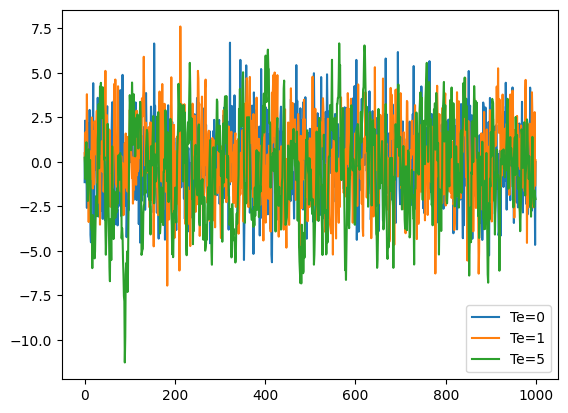

In [111]:
import matplotlib.pyplot as plt

T = 1000

Te1 = 0
ts1 = red_noise(
    T,
    Te=Te1,
    )

Te2 = 1
ts2 = red_noise(
    T,
    Te=Te2,
    )

Te3 = 5
ts3 = red_noise(
    T,
    Te=Te3,
    )

plt.plot(ts1, label='Te={}'.format(Te1))
plt.plot(ts2, label='Te={}'.format(Te2))
plt.plot(ts3, label='Te={}'.format(Te3))
plt.legend()
plt.show()

Text(0.5, 0, 'Lag')

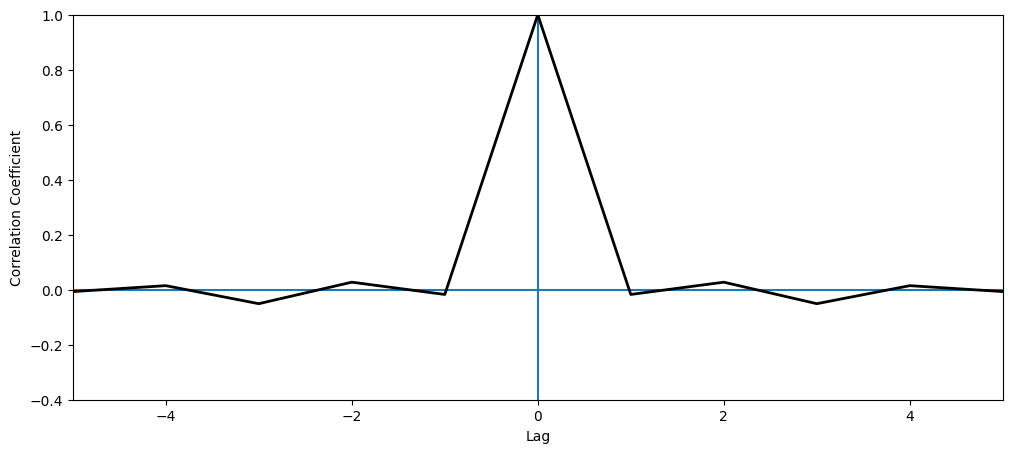

In [75]:
#np.correlate actually gives the covariance. We need to find the covariance of the deviations from the mean and then
#divide the the tau=0 covariance, i.e., the variance to get the correlation
ts = ts1
Tcorr = np.correlate((ts-np.mean(ts)),(ts-np.mean(ts))/(len(ts)*np.var(ts)),'same')

#plot the autocorrelation function
fig = plt.figure(figsize=(12,5))

# x-value for plotting
x = np.arange(0,len(ts),1)
series = [i-len(ts)/2.0 for i in x]

#plot series
plt.axhline(0)
plt.axvline(0)
plt.plot(series,Tcorr,'k',linewidth=2)
plt.xlim(-5,5)
plt.ylim(-0.4,1)
plt.ylabel('Correlation Coefficient')
plt.xlabel('Lag')

## Fuzzy Edges

- the shift signal (meaning the magnitude) becomes smaller and smaller closer to the edge of the cluster
    - this can be achieved by using a gauss-correlation

Question:<br>
If the magnitude of the shift is altered, does that mean that the cells end up at a different value in the end? 

In [126]:
from ponds.shapegen import ELLIPSIS

lat_size = 10
lon_size = 10

shapegen = ELLIPSIS(
    center_lat=0,
    center_lon=0,
    ecc_lat=2,
    ecc_lon=2,
)
    
    
shape = shapegen.make_shape(
    lats = np.arange(lat_size) - lat_size // 2,
    lons = np.arange(lon_size) - lon_size // 2,
    )

print(shape)

[[False False False False False False False False False False]
 [False False False False False False False False False False]
 [False False False False False False False False False False]
 [False False False False False  True False False False False]
 [False False False False  True  True  True False False False]
 [False False False  True  True  True  True  True False False]
 [False False False False  True  True  True False False False]
 [False False False False False  True False False False False]
 [False False False False False False False False False False]
 [False False False False False False False False False False]]
